In [1]:
import pandas as pd
import numpy as np
import re
import ast
import warnings

warnings.filterwarnings("ignore")

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Recommendation System
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Knowledge Graph
import networkx as nx

In [2]:
# Path to dataset
DATA_PATH = r"D:\Huawei & NTI\course_recommender_app\Coursera.csv"

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

display(df.head())

Dataset loaded successfully!
Number of rows: 3522
Number of columns: 7


,Course Name,University,Difficulty Level,Course Rating,Course URL,Course Description,Skills
0,Write A Feature Length Screenplay For Film Or ...,Michigan State University,Beginner,4.8,https://www.coursera.org/learn/write-a-feature...,Write a Full Length Feature Film Script In th...,Drama Comedy peering screenwriting film D...
1,Business Strategy: Business Model Canvas Analy...,Coursera Project Network,Beginner,4.8,https://www.coursera.org/learn/canvas-analysis...,"By the end of this guided project, you will be...",Finance business plan persona (user experien...
2,Silicon Thin Film Solar Cells,�cole Polytechnique,Advanced,4.1,https://www.coursera.org/learn/silicon-thin-fi...,This course consists of a general presentation...,chemistry physics Solar Energy film lambda...
3,Finance for Managers,IESE Business School,Intermediate,4.8,https://www.coursera.org/learn/operational-fin...,"When it comes to numbers, there is always more...",accounts receivable dupont analysis analysis...
4,Retrieve Data using Single-Table SQL Queries,Coursera Project Network,Beginner,4.6,https://www.coursera.org/learn/single-table-sq...,In this course you�ll learn how to effectively...,Data Analysis select (sql) database manageme...


In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Column Names:
['Course Name', 'University', 'Difficulty Level', 'Course Rating', 'Course URL', 'Course Description', 'Skills']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3522 entries, 0 to 3521
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Course Name         3522 non-null   object
 1   University          3522 non-null   object
 2   Difficulty Level    3522 non-null   object
 3   Course Rating       3522 non-null   object
 4   Course URL          3522 non-null   object
 5   Course Description  3522 non-null   object
 6   Skills              3522 non-null   object
dtypes: object(7)
memory usage: 192.7+ KB


In [4]:
print("Missing Values:")
display(df.isnull().sum().sort_values(ascending=False))

Missing Values:


Course Name           0
University            0
Difficulty Level      0
Course Rating         0
Course URL            0
Course Description    0
Skills                0
dtype: int64

In [5]:
print("Missing Values:")
display(df.isnull().sum().sort_values(ascending=False))

Missing Values:


Course Name           0
University            0
Difficulty Level      0
Course Rating         0
Course URL            0
Course Description    0
Skills                0
dtype: int64

In [6]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 98


In [7]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['course_name', 'university', 'difficulty_level', 'course_rating', 'course_url', 'course_description', 'skills']


In [8]:
for column in df.columns:
    print(column)

course_name
university
difficulty_level
course_rating
course_url
course_description
skills


In [9]:
# Possible column mapping
column_mapping = {}

if "course_name" not in df.columns:
    possible_names = ["course", "title", "course_title", "name"]
    for col in possible_names:
        if col in df.columns:
            column_mapping[col] = "course_name"
            break

if "difficulty_level" not in df.columns:
    possible_levels = ["level", "difficulty", "course_level"]
    for col in possible_levels:
        if col in df.columns:
            column_mapping[col] = "difficulty_level"
            break

if "course_rating" not in df.columns:
    possible_ratings = ["rating", "course_rating"]
    for col in possible_ratings:
        if col in df.columns:
            column_mapping[col] = "course_rating"
            break

if "course_description" not in df.columns:
    possible_desc = ["description", "course_description", "summary"]
    for col in possible_desc:
        if col in df.columns:
            column_mapping[col] = "course_description"
            break

if "skills" not in df.columns:
    possible_skills = ["skill", "skills"]
    for col in possible_skills:
        if col in df.columns:
            column_mapping[col] = "skills"
            break

df = df.rename(columns=column_mapping)

print("Final columns:")
print(df.columns.tolist())

Final columns:
['course_name', 'university', 'difficulty_level', 'course_rating', 'course_url', 'course_description', 'skills']


In [10]:
required_columns = [
    "course_name",
    "difficulty_level",
    "course_rating",
    "course_description",
    "skills"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("Missing columns:")
    print(missing_columns)
else:
    print("All required columns are available!")

All required columns are available!


In [11]:
# Remove duplicate courses
df = df.drop_duplicates(subset=["course_name"]).reset_index(drop=True)

# Fill missing text values
text_columns = [
    "course_name",
    "course_description",
    "skills",
    "difficulty_level"
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].fillna("").astype(str)

# Convert rating to numeric
df["course_rating"] = pd.to_numeric(
    df["course_rating"],
    errors="coerce"
)

# Fill missing ratings with dataset median
df["course_rating"] = df["course_rating"].fillna(
    df["course_rating"].median()
)

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (3416, 7)


In [12]:
def clean_text(text):
    """
    Clean text for NLP processing.
    """

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Remove special characters
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [13]:
df["clean_course_name"] = df["course_name"].apply(clean_text)

df["clean_description"] = (
    df["course_description"]
    .apply(clean_text)
)

df["clean_skills"] = (
    df["skills"]
    .apply(clean_text)
)

df["clean_level"] = (
    df["difficulty_level"]
    .apply(clean_text)
)

In [14]:
df["course_profile"] = (
    df["clean_course_name"] + " " +
    df["clean_course_name"] + " " +
    df["clean_skills"] + " " +
    df["clean_skills"] + " " +
    df["clean_description"] + " " +
    df["clean_level"]
)

display(
    df[
        [
            "course_name",
            "difficulty_level",
            "course_rating",
            "course_profile"
        ]
    ].head()
)

,course_name,difficulty_level,course_rating,course_profile
0,Write A Feature Length Screenplay For Film Or ...,Beginner,4.8,write a feature length screenplay for film or ...
1,Business Strategy: Business Model Canvas Analy...,Beginner,4.8,business strategy business model canvas analys...
2,Silicon Thin Film Solar Cells,Advanced,4.1,silicon thin film solar cells silicon thin fil...
3,Finance for Managers,Intermediate,4.8,finance for managers finance for managers acco...
4,Retrieve Data using Single-Table SQL Queries,Beginner,4.6,retrieve data using single table sql queries r...


In [15]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    min_df=1
)

tfidf_matrix = tfidf.fit_transform(
    df["course_profile"]
)

print("TF-IDF Matrix Shape:")
print(tfidf_matrix.shape)

TF-IDF Matrix Shape:
(3416, 10000)


In [16]:
cosine_sim = cosine_similarity(tfidf_matrix)

print("Cosine Similarity Matrix Shape:")
print(cosine_sim.shape)

Cosine Similarity Matrix Shape:
(3416, 3416)


In [17]:
course_indices = pd.Series(
    df.index,
    index=df["course_name"].str.lower()
).drop_duplicates()


def recommend_similar_courses(
    course_name,
    top_n=5
):
    """
    Recommend courses similar to a given course.
    """

    course_key = course_name.lower().strip()

    if course_key not in course_indices:
        return pd.DataFrame(
            columns=[
                "course_name",
                "difficulty_level",
                "course_rating",
                "similarity_score"
            ]
        )

    idx = course_indices[course_key]

    similarity_scores = list(
        enumerate(cosine_sim[idx])
    )

    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    similarity_scores = similarity_scores[1:top_n + 1]

    course_ids = [
        i[0]
        for i in similarity_scores
    ]

    scores = [
        i[1]
        for i in similarity_scores
    ]

    recommendations = df.iloc[
        course_ids
    ][
        [
            "course_name",
            "difficulty_level",
            "course_rating"
        ]
    ].copy()

    recommendations["similarity_score"] = scores

    recommendations["similarity_score"] = (
        recommendations["similarity_score"]
        .round(3)
    )

    return recommendations.reset_index(drop=True)

In [18]:
example_course = df["course_name"].iloc[0]

print("Input Course:")
print(example_course)

recommendations = recommend_similar_courses(
    example_course,
    top_n=5
)

display(recommendations)

Input Course:
Write A Feature Length Screenplay For Film Or Television


,course_name,difficulty_level,course_rating,similarity_score
0,Script Writing: Write a Pilot Episode for a TV...,Advanced,4.3,0.620
1,Write Your First Novel,Beginner,3.5,0.463
2,Transmedia Writing,Advanced,4.1,0.460
3,Creative Writing: The Craft of Style,Advanced,4.7,0.281
4,Writing Stories About Ourselves,Advanced,3.7,0.280


In [19]:
example_course = df["course_name"].iloc[0]

print("Input Course:")
print(example_course)

recommendations = recommend_similar_courses(
    example_course,
    top_n=5
)

display(recommendations)

Input Course:
Write A Feature Length Screenplay For Film Or Television


,course_name,difficulty_level,course_rating,similarity_score
0,Script Writing: Write a Pilot Episode for a TV...,Advanced,4.3,0.620
1,Write Your First Novel,Beginner,3.5,0.463
2,Transmedia Writing,Advanced,4.1,0.460
3,Creative Writing: The Craft of Style,Advanced,4.7,0.281
4,Writing Stories About Ourselves,Advanced,3.7,0.280


In [20]:
def create_user_profile(
    skills,
    interests,
    level=""
):
    """
    Create a textual representation of the user's profile.
    """

    if isinstance(skills, list):
        skills = " ".join(skills)

    if isinstance(interests, list):
        interests = " ".join(interests)

    user_profile = (
        str(skills) + " " +
        str(interests) + " " +
        str(level)
    )

    return clean_text(user_profile)

In [21]:
def recommend_courses_for_user(
    skills,
    interests,
    level="",
    top_n=5
):

    user_profile = create_user_profile(
        skills,
        interests,
        level
    )

    # Transform user profile using the same TF-IDF model
    user_vector = tfidf.transform(
        [user_profile]
    )

    # Calculate similarity between user and all courses
    similarity_scores = cosine_similarity(
        user_vector,
        tfidf_matrix
    ).flatten()

    # Copy dataset
    results = df.copy()

    results["similarity_score"] = similarity_scores

    # Optional level boosting
    if level:

        level_clean = clean_text(level)

        results["level_match"] = (
            results["clean_level"]
            .str.contains(
                level_clean,
                case=False,
                na=False
            )
            .astype(int)
        )

        # Small boost for matching level
        results["final_score"] = (
            results["similarity_score"] * 0.90 +
            results["level_match"] * 0.10
        )

    else:
        results["final_score"] = (
            results["similarity_score"]
        )

    # Sort
    results = results.sort_values(
        "final_score",
        ascending=False
    )

    # Return top courses
    output_columns = [
        "course_name",
        "difficulty_level",
        "course_rating",
        "similarity_score"
    ]

    return (
        results[
            output_columns
        ]
        .head(top_n)
        .reset_index(drop=True)
    )

In [22]:
user_skills = [
    "Python",
    "Machine Learning",
    "Pandas"
]

user_interests = [
    "Artificial Intelligence",
    "Data Science"
]

user_level = "Intermediate"

user_recommendations = recommend_courses_for_user(
    skills=user_skills,
    interests=user_interests,
    level=user_level,
    top_n=5
)

display(user_recommendations)

,course_name,difficulty_level,course_rating,similarity_score
0,Business Application of Machine Learning and A...,Intermediate,3.8,0.406881
1,Introduction to Artificial Intelligence (AI),Conversant,4.7,0.505341
2,Intermediate Pandas Python Library for Data Sc...,Beginner,4.4,0.503874
3,Introduction to Applied Machine Learning,Intermediate,4.7,0.357824
4,"The Power of Machine Learning: Boost Business,...",Intermediate,5.0,0.315208


In [23]:
def display_recommendations(
    skills,
    interests,
    level="",
    top_n=5
):

    results = recommend_courses_for_user(
        skills=skills,
        interests=interests,
        level=level,
        top_n=top_n
    )

    print("=" * 70)
    print("AI COURSE RECOMMENDATION SYSTEM")
    print("=" * 70)

    print("\nUser Skills:")
    print(", ".join(skills))

    print("\nUser Interests:")
    print(", ".join(interests))

    print("\nUser Level:")
    print(level)

    print("\nTop Recommended Courses:")
    print("-" * 70)

    for i, row in results.iterrows():

        print(
            f"{i+1}. {row['course_name']}"
        )

        print(
            f"   Level: {row['difficulty_level']}"
        )

        print(
            f"   Rating: {row['course_rating']}"
        )

        print(
            f"   Similarity Score: "
            f"{row['similarity_score']:.3f}"
        )

        print("-" * 70)

    return results

In [24]:
results = display_recommendations(
    skills=[
        "Python",
        "Machine Learning",
        "Pandas"
    ],
    interests=[
        "Artificial Intelligence",
        "Data Science"
    ],
    level="Intermediate",
    top_n=5
)

AI COURSE RECOMMENDATION SYSTEM

User Skills:
Python, Machine Learning, Pandas

User Interests:
Artificial Intelligence, Data Science

User Level:
Intermediate

Top Recommended Courses:
----------------------------------------------------------------------
1. Business Application of Machine Learning and Artificial Intelligence in Healthcare
   Level: Intermediate
   Rating: 3.8
   Similarity Score: 0.407
----------------------------------------------------------------------
2. Introduction to Artificial Intelligence (AI)
   Level: Conversant
   Rating: 4.7
   Similarity Score: 0.505
----------------------------------------------------------------------
3. Intermediate Pandas Python Library for Data Science
   Level: Beginner
   Rating: 4.4
   Similarity Score: 0.504
----------------------------------------------------------------------
4. Introduction to Applied Machine Learning
   Level: Intermediate
   Rating: 4.7
   Similarity Score: 0.358
-------------------------------------------

In [25]:
G = nx.Graph()

user_name = "User"

user_skills = [
    "Python",
    "Machine Learning",
    "Pandas"
]

user_interests = [
    "Artificial Intelligence",
    "Data Science"
]

user_level = "Intermediate"

In [26]:
# Add User
G.add_node(
    user_name,
    node_type="User"
)

# Add Skills
for skill in user_skills:

    G.add_node(
        skill,
        node_type="Skill"
    )

    G.add_edge(
        user_name,
        skill,
        relation="HAS_SKILL"
    )


# Add Topics
for topic in user_interests:

    G.add_node(
        topic,
        node_type="Topic"
    )

    G.add_edge(
        user_name,
        topic,
        relation="INTERESTED_IN"
    )

In [27]:
skill_to_topics = {
    "Python": [
        "Data Science",
        "Programming",
        "Machine Learning"
    ],

    "Machine Learning": [
        "Artificial Intelligence",
        "Data Science"
    ],

    "Pandas": [
        "Data Science",
        "Data Analysis"
    ]
}

In [28]:
for skill, topics in skill_to_topics.items():

    if skill in user_skills:

        for topic in topics:

            G.add_node(
                topic,
                node_type="Topic"
            )

            G.add_edge(
                skill,
                topic,
                relation="RELATED_TO"
            )

In [29]:
recommended_courses = results["course_name"].tolist()

for course in recommended_courses:

    G.add_node(
        course,
        node_type="Course"
    )

    # Connect courses to user's interests/topics
    course_text = clean_text(
        df.loc[
            df["course_name"] == course,
            "course_profile"
        ].iloc[0]
    )

    for topic in user_interests:

        if clean_text(topic) in course_text:

            G.add_edge(
                topic,
                course,
                relation="RECOMMENDS"
            )

In [30]:
for course in recommended_courses:

    course_row = df[
        df["course_name"] == course
    ].iloc[0]

    course_skills = course_row["clean_skills"]

    for skill in user_skills:

        if clean_text(skill) in course_skills:

            G.add_edge(
                skill,
                course,
                relation="TEACHES"
            )

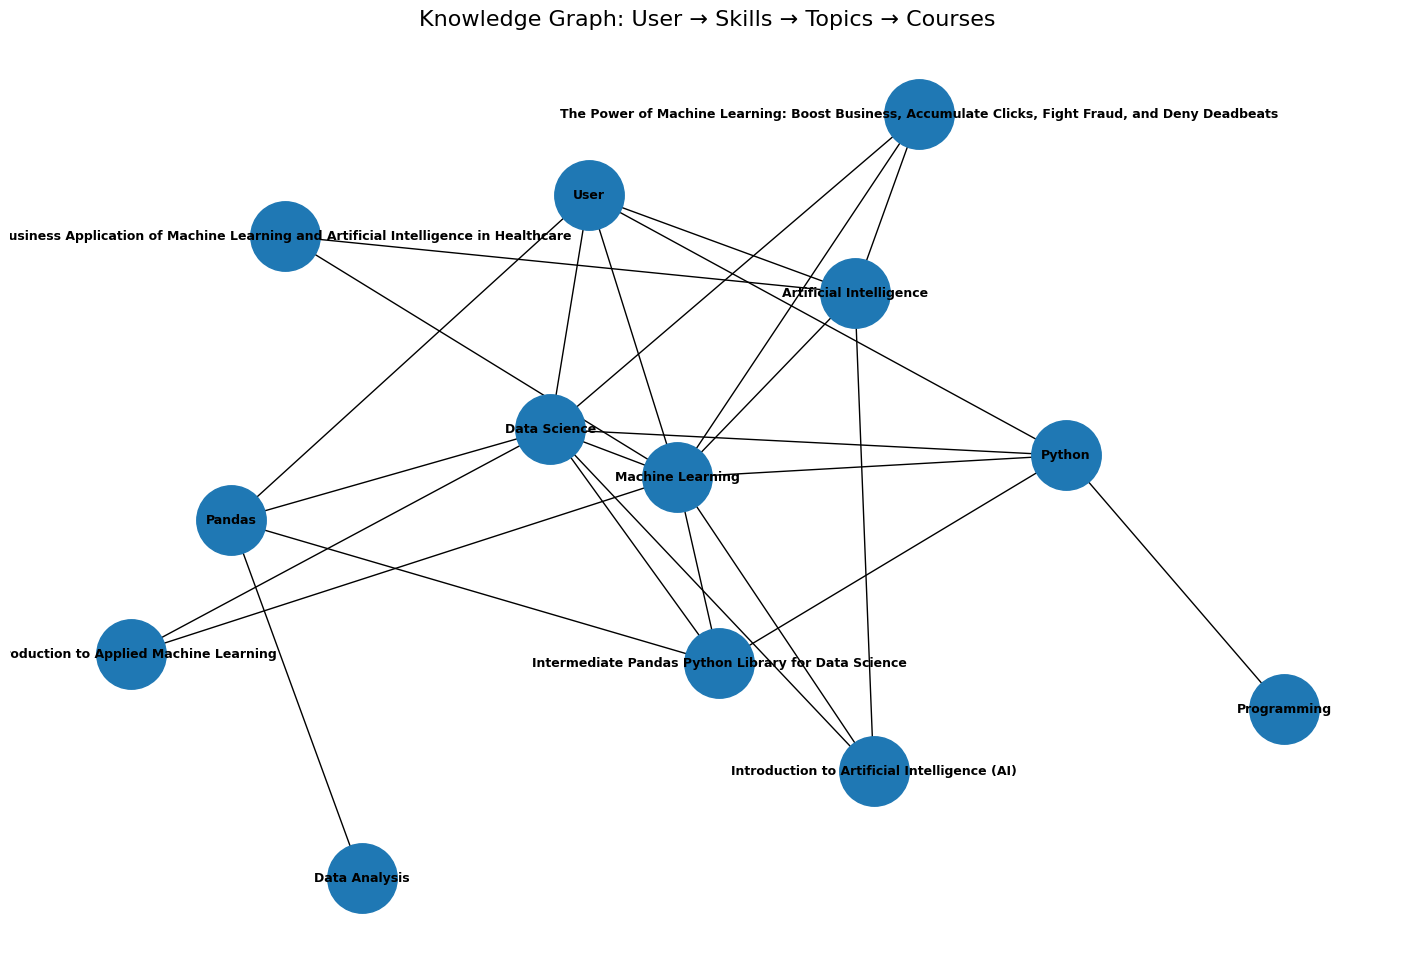

In [31]:
plt.figure(figsize=(18, 12))

pos = nx.spring_layout(
    G,
    seed=42,
    k=1.5
)

nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_size=2500,
    font_size=9,
    font_weight="bold"
)

plt.title(
    "Knowledge Graph: User → Skills → Topics → Courses",
    fontsize=16
)

plt.axis("off")
plt.show()

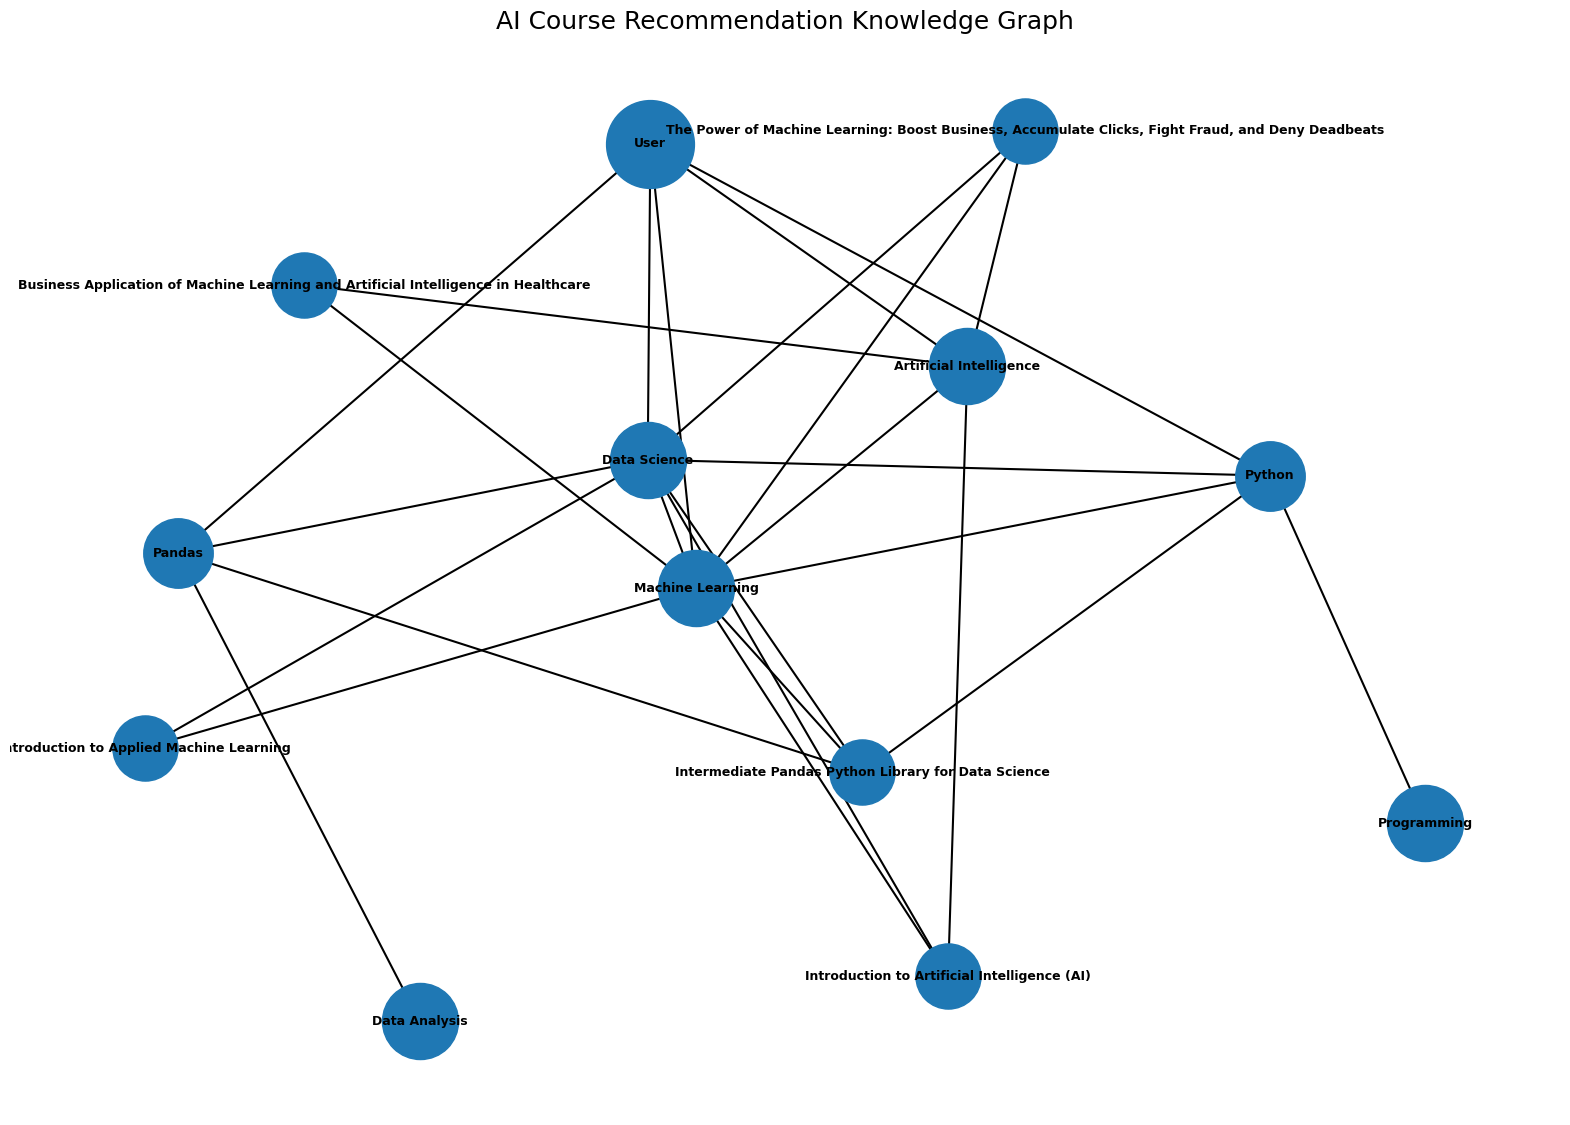

In [32]:
plt.figure(figsize=(20, 14))

pos = nx.spring_layout(
    G,
    seed=42,
    k=1.7
)

node_types = nx.get_node_attributes(
    G,
    "node_type"
)

users = [
    node for node, node_type
    in node_types.items()
    if node_type == "User"
]

skills = [
    node for node, node_type
    in node_types.items()
    if node_type == "Skill"
]

topics = [
    node for node, node_type
    in node_types.items()
    if node_type == "Topic"
]

courses = [
    node for node, node_type
    in node_types.items()
    if node_type == "Course"
]

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=users,
    node_size=4000
)

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=skills,
    node_size=2500
)

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=topics,
    node_size=3000
)

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=courses,
    node_size=2200
)

nx.draw_networkx_edges(
    G,
    pos,
    width=1.5
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=9,
    font_weight="bold"
)

plt.title(
    "AI Course Recommendation Knowledge Graph",
    fontsize=18
)

plt.axis("off")
plt.show()

In [33]:
print("Knowledge Graph Relationships")
print("=" * 60)

for source, target, data in G.edges(data=True):

    print(
        f"{source} "
        f"--[{data.get('relation', '')}]--> "
        f"{target}"
    )

Knowledge Graph Relationships
User --[HAS_SKILL]--> Python
User --[HAS_SKILL]--> Machine Learning
User --[HAS_SKILL]--> Pandas
User --[INTERESTED_IN]--> Artificial Intelligence
User --[INTERESTED_IN]--> Data Science
Python --[RELATED_TO]--> Data Science
Python --[RELATED_TO]--> Programming
Python --[RELATED_TO]--> Machine Learning
Python --[TEACHES]--> Intermediate Pandas Python Library for Data Science
Machine Learning --[RELATED_TO]--> Artificial Intelligence
Machine Learning --[RELATED_TO]--> Data Science
Machine Learning --[TEACHES]--> Business Application of Machine Learning and Artificial Intelligence in Healthcare
Machine Learning --[TEACHES]--> Introduction to Artificial Intelligence (AI)
Machine Learning --[TEACHES]--> Intermediate Pandas Python Library for Data Science
Machine Learning --[TEACHES]--> Introduction to Applied Machine Learning
Machine Learning --[TEACHES]--> The Power of Machine Learning: Boost Business, Accumulate Clicks, Fight Fraud, and Deny Deadbeats
Pandas 

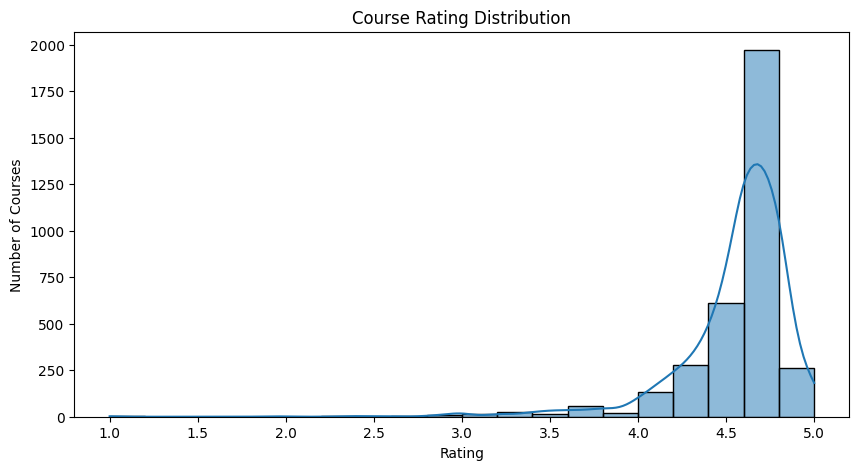

In [34]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["course_rating"],
    bins=20,
    kde=True
)

plt.title("Course Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Courses")

plt.show()

In [35]:
top_rated = (
    df[
        [
            "course_name",
            "difficulty_level",
            "course_rating"
        ]
    ]
    .sort_values(
        "course_rating",
        ascending=False
    )
    .head(10)
)

display(top_rated)

,course_name,difficulty_level,course_rating
2335,Chemical Biology,Intermediate,5.0
3300,Population Health: Predictive Analytics,Advanced,5.0
3375,Cluster Analysis using RCmdr,Beginner,5.0
1833,Artificial Intelligence Privacy and Convenience,Advanced,5.0
1844,Intermediate Intel� Distribution of OpenVINO� ...,Advanced,5.0
1309,The Art & Science of Product Management,Beginner,5.0
108,Big data and Language 2,Advanced,5.0
1316,Getting Started with ProfitBooks,Beginner,5.0
2104,Conduct a Cost-Benefit Analysis in Google Sheets,Beginner,5.0
1859,Stock Valuation with Dividend Discount Model,Beginner,5.0


In [36]:
skills_input = input(
    "Enter your skills separated by commas: "
)

interests_input = input(
    "Enter your interests separated by commas: "
)

level_input = input(
    "Enter your level (Beginner/Intermediate/Advanced): "
)

skills = [
    x.strip()
    for x in skills_input.split(",")
    if x.strip()
]

interests = [
    x.strip()
    for x in interests_input.split(",")
    if x.strip()
]

recommendations = display_recommendations(
    skills=skills,
    interests=interests,
    level=level_input,
    top_n=5
)

AI COURSE RECOMMENDATION SYSTEM

User Skills:
Python, Machine Learning, SQL

User Interests:
Artificial Intelligence, Data Science

User Level:
Intermediate

Top Recommended Courses:
----------------------------------------------------------------------
1. Business Application of Machine Learning and Artificial Intelligence in Healthcare
   Level: Intermediate
   Rating: 3.8
   Similarity Score: 0.421
----------------------------------------------------------------------
2. Introduction to Artificial Intelligence (AI)
   Level: Conversant
   Rating: 4.7
   Similarity Score: 0.523
----------------------------------------------------------------------
3. Introduction to Applied Machine Learning
   Level: Intermediate
   Rating: 4.7
   Similarity Score: 0.370
----------------------------------------------------------------------
4. Big Data, Artificial Intelligence, and Ethics
   Level: Beginner
   Rating: 4.5
   Similarity Score: 0.441
----------------------------------------------------